# Classical AI: Informed (Heuristic) Search

> **Who is this for:** a beginner who has finished the previous notebook on uninformed search, or a student revising A\* for an exam or interview.
>
> **What you will learn**
> - What a **heuristic** is, and the two properties that matter: **admissible** and **consistent**, with the proofs in plain words
> - **Dominance** between heuristics, and how to invent heuristics from **relaxed problems**
> - **Greedy best-first search** vs **A\***: fast but sloppy vs optimal, on a grid with a trap and on our road map
> - The **8-puzzle** with the **misplaced-tiles** and **Manhattan-distance** heuristics, including a **solvability check** by counting inversions
> - **IDA\***, **weighted A\***, and how memory-bounded searches (RBFS, SMA\*) deal with A\*'s memory problem
> - The **effective branching factor** $b^*$, a single number for how well a heuristic works
> - How an **inadmissible** heuristic can return a **non-optimal** path
>
> **Prerequisites:** [`02_uninformed_search.ipynb`](02_uninformed_search.ipynb) (nodes, frontier, BFS, UCS) and [`01_types_of_ai_and_intelligent_agents.ipynb`](01_types_of_ai_and_intelligent_agents.ipynb) (problem formulation).
>
> **Time needed:** about 2-3 hours.
>
> **Runs on:** CPU, no API key, about a minute to run everything.
>
> **Optional track:** part of the **university-level fundamentals track**. We recommend it for BS/MS AI students and for interview prep.

## Explained simply

Informed search is search with a **sense of direction**. Instead of checking places in a fixed order, the computer uses a quick guess, called a **heuristic**, of how far each place still is from the goal. If you are driving to the seaside, you prefer roads that head towards the sea, even before you know they get there. **A\*** adds the distance already travelled to the guessed distance still to go, and always continues from the place where that total is smallest. As long as the guess **never overestimates**, A\* is guaranteed to find the best route while checking far fewer places than blind search. This is how characters in video games find their way round walls, and how map apps plan routes quickly.

**A tiny example.** You are in town A and want to reach town D. There are two routes: A → B → D is 4 + 5 = 9 km, and A → C → D is 2 + 9 = 11 km. The straight-line guesses are: B is 4 km from D, and C is 8 km from D. A\* scores B as 4 travelled + 4 guessed = 8, and C as 2 + 8 = 10. It continues from B first and reaches D with a total of 9 km. The best remaining score is now C's 10, which is already worse than 9, so A\* stops: 9 km is the answer, and it never had to explore the road from C to D.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Heuristic | a quick, cheap guess of how far you still have to go | "as the crow flies" distance on a map |
| A\* | continue from the place where (distance so far + guess) is smallest | game pathfinding, robot navigation, sat-navs |
| Admissible heuristic | a guess that never says the goal is farther away than it really is | straight-line distance is never longer than the road |

## Contents

1. Heuristics: giving search a sense of direction
2. Admissible and consistent heuristics, with proofs
3. Greedy best-first search vs A\* on the road map
4. Greedy vs A\* on a grid with obstacles: zero vs Euclidean vs Manhattan
5. The 8-puzzle: solvability, two heuristics, dominance and relaxed problems
6. Effective branching factor
7. IDA\*: A\* with the memory of depth-first search
8. Weighted A\*: trading optimality for speed
9. When the heuristic overestimates: non-optimal paths
10. Memory-bounded search: RBFS and SMA\*
11. How this connects to modern AI
12. Recap, practice problems, further reading

In [1]:
import math
import random
import time
import heapq
import itertools
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

SEED = 11
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 100

We reuse the small search toolkit from notebook 02: `Problem`, `Node`, `expand` and `Stats`.

In [2]:
class Problem:
    def __init__(self, initial, goal=None):
        self.initial, self.goal = initial, goal
    def actions(self, state):             raise NotImplementedError
    def result(self, state, action):      raise NotImplementedError
    def is_goal(self, state):             return state == self.goal
    def action_cost(self, s, a, s2):      return 1

class Node:
    __slots__ = ("state", "parent", "action", "path_cost", "depth")
    def __init__(self, state, parent=None, action=None, path_cost=0):
        self.state, self.parent, self.action, self.path_cost = state, parent, action, path_cost
        self.depth = 0 if parent is None else parent.depth + 1

def expand(problem, node):
    s = node.state
    for a in problem.actions(s):
        s2 = problem.result(s, a)
        yield Node(s2, node, a, node.path_cost + problem.action_cost(s, a, s2))

def path_states(node):
    out = []
    while node is not None:
        out.append(node.state); node = node.parent
    return out[::-1]

class Stats:
    def __init__(self, name):
        self.name, self.expanded, self.generated, self.max_memory = name, [], 0, 0

## 1. Heuristics: giving search a sense of direction

> 💬 **In plain English:** a heuristic is a quick guess of how far the goal is, so the search can head the right way.

**Intuition.** Uniform-cost search spreads out evenly in every direction, like a ripple. If you are driving from Ashford to Lakeside and Lakeside is to the south-east, it is silly to explore towns to the north-west with the same enthusiasm. A **heuristic** is a rule of thumb that estimates how far a state is from the goal, so the search can lean towards the goal.

**Definitions.**
- A **heuristic function** $h(n)$ estimates the cost of the cheapest path from the state at node $n$ to a goal state. It depends only on the *state*, and $h(\text{goal}) = 0$.
- $g(n)$ is the cost already paid to reach $n$ (from notebook 02).
- $h^*(n)$ is the **true** cheapest cost from $n$ to a goal. We usually don't know it; if we did, there would be nothing left to search.
- **Informed search** (or **heuristic search**) uses $h$ to decide which node to expand next.

All the algorithms in this notebook are versions of **best-first search**: always expand the node with the smallest value of an **evaluation function** $f(n)$:

| Algorithm | $f(n)$ | Idea |
|---|---|---|
| Uniform-cost search | $g(n)$ | cheapest so far (ignores the goal) |
| **Greedy best-first** | $h(n)$ | looks closest to the goal (ignores the past) |
| **A\*** | $g(n) + h(n)$ | estimated cost of the cheapest solution *through* $n$ |
| **Weighted A\*** | $g(n) + w \cdot h(n)$, $w > 1$ | in between: leans towards the goal |

**Our first heuristic.** On the road map, the **straight-line distance** (SLD) from a town to Lakeside is a natural $h$: a road can never be shorter than the straight line.

In [3]:
CITY_XY = {
    "Ashford": (10, 80), "Brookvale": (30, 92), "Cedar Falls": (22, 58), "Dunmore": (48, 78),
    "Elmstead": (42, 50), "Fairhaven": (70, 88), "Glenwood": (68, 56), "Harborview": (92, 72),
    "Ironbridge": (15, 28), "Juniper": (45, 22), "Kingsport": (78, 32), "Lakeside": (96, 12),
}
ROADS = [
    ("Ashford", "Brookvale", 26), ("Ashford", "Cedar Falls", 28), ("Brookvale", "Dunmore", 25),
    ("Cedar Falls", "Dunmore", 40), ("Cedar Falls", "Elmstead", 24), ("Cedar Falls", "Ironbridge", 34),
    ("Dunmore", "Fairhaven", 27), ("Dunmore", "Elmstead", 33), ("Elmstead", "Glenwood", 31),
    ("Elmstead", "Juniper", 30), ("Fairhaven", "Harborview", 30), ("Fairhaven", "Glenwood", 36),
    ("Glenwood", "Harborview", 32), ("Glenwood", "Kingsport", 29), ("Ironbridge", "Juniper", 33),
    ("Juniper", "Kingsport", 38), ("Kingsport", "Lakeside", 29), ("Harborview", "Lakeside", 64),
]
road_map = {c: {} for c in CITY_XY}
for a, b, km in ROADS:
    road_map[a][b] = km; road_map[b][a] = km

class RouteProblem(Problem):
    def __init__(self, initial, goal, graph):
        super().__init__(initial, goal); self.graph = graph
    def actions(self, city):          return sorted(self.graph[city])
    def result(self, city, action):   return action
    def action_cost(self, c, a, c2):  return self.graph[c][c2]

route = RouteProblem("Ashford", "Lakeside", road_map)
G_map = nx.Graph(); G_map.add_weighted_edges_from(ROADS)

def h_sld(city):
    # straight-line distance to Lakeside (km)
    return math.dist(CITY_XY[city], CITY_XY["Lakeside"])

h_star = nx.single_source_dijkstra_path_length(G_map, "Lakeside")   # true remaining cost h*(n), for checking
table = pd.DataFrame({"h_SLD (km)": {c: round(h_sld(c), 1) for c in CITY_XY},
                      "true h* (km)": h_star}).sort_values("h_SLD (km)")
print(table.to_string())

             h_SLD (km)  true h* (km)
Lakeside            0.0             0
Kingsport          26.9            29
Juniper            52.0            67
Glenwood           52.2            58
Harborview         60.1            64
Elmstead           66.0            89
Fairhaven          80.3            94
Dunmore            81.6           121
Ironbridge         82.6           100
Cedar Falls        87.1           113
Brookvale         103.7           146
Ashford           109.6           141


**What just happened?** For every town, the straight-line distance (left) is at most the true road distance (right). An estimate that never overestimates is called **admissible**. That property is what makes A\* optimal, as the next section proves.

## 2. Admissible and consistent heuristics

> 💬 **In plain English:** if your guess never overestimates, A\* is guaranteed to find the best path; here is why.

### Definitions

- $h$ is **admissible** if it **never overestimates**: $h(n) \le h^*(n)$ for every node $n$. An admissible heuristic is *optimistic*.
- $h$ is **consistent** (or **monotone**) if for every node $n$ and every successor $n'$ reached by action $a$:
$$h(n) \;\le\; c(n, a, n') + h(n').$$
This is a **triangle inequality**: the estimate from $n$ cannot be more than "one step to $n'$, then the estimate from $n'$".

```
            c(n, a, n')
      n  --------------->  n'
        \                 /
   h(n)  \               /  h(n')
          v             v
               goal
   consistent:  h(n) <= c(n, a, n') + h(n')
```

### Proof 1: every consistent heuristic is admissible

Take any node $n$ and a cheapest path from it to the goal: $n = n_0, n_1, \dots, n_k = \text{goal}$. Apply consistency at each step and add them up:
$h(n_0) \le c_1 + h(n_1) \le c_1 + c_2 + h(n_2) \le \dots \le c_1 + \dots + c_k + h(\text{goal}).$
Since $h(\text{goal}) = 0$ and $c_1 + \dots + c_k = h^*(n)$, we get $h(n) \le h^*(n)$. ∎

The reverse is **not** true: some admissible heuristics are inconsistent. You will see one below.

### Proof 2: A\* with an admissible heuristic returns an optimal solution

Let $C^*$ be the optimal cost. Suppose A\* were about to return a goal node $G_2$ with cost $g(G_2) > C^*$.
1. At that moment, some node $n$ on an optimal path must still be in the frontier (the optimal path starts at the root, which was expanded, and has not been followed to the end yet).
2. For that node, $f(n) = g(n) + h(n) \le g(n) + h^*(n) = C^*$, because $h$ is admissible and $n$ is on an optimal path.
3. For the goal node, $f(G_2) = g(G_2) + 0 > C^*$.
4. So $f(n) < f(G_2)$, and A\* would expand $n$ before $G_2$. Contradiction. ∎

### Proof 3: with a consistent heuristic, A\* graph search never needs to re-open a state

1. Along any path, $f$ never decreases: $f(n') = g(n) + c + h(n') \ge g(n) + h(n) = f(n)$, by consistency.
2. So A\* expands nodes in **non-decreasing order of $f$**. It draws **contours** of equal $f$ around the start, like the contour lines of a hill.
3. The first time A\* expands a state, it has reached that state by a cheapest path. If a cheaper path existed, its last node in the frontier would have a smaller $f$ and would have come out first.

So with a consistent $h$, a state's first expansion is final. With an admissible but **inconsistent** $h$, a cheaper path to an already-expanded state can turn up later. An implementation that never re-opens expanded states ("closed list") can then return a non-optimal answer. Let's show that with a tiny example.

**Is SLD consistent?** Yes: $h(n) = \text{SLD}(n) \le \text{SLD}(n, n') + \text{SLD}(n') \le \text{road}(n, n') + h(n')$, by the triangle inequality and because roads are never shorter than straight lines. We check both properties in code too.

In [4]:
def is_admissible(h, h_true, states):
    return all(h(s) <= h_true[s] + 1e-9 for s in states)

def is_consistent(h, problem, states):
    for s in states:
        for a in problem.actions(s):
            s2 = problem.result(s, a)
            if h(s) > problem.action_cost(s, a, s2) + h(s2) + 1e-9:
                return False
    return True

print("SLD admissible on the map:", is_admissible(h_sld, h_star, CITY_XY))
print("SLD consistent on the map:", is_consistent(h_sld, route, CITY_XY))
assert is_admissible(h_sld, h_star, CITY_XY) and is_consistent(h_sld, route, CITY_XY)

SLD admissible on the map: True
SLD consistent on the map: True


Now the general best-first search. Its `reopen` switch decides what happens when a cheaper path to an already-expanded state is found:
- `reopen=True` (AIMA 4th edition's version): put the state back in the frontier with the better cost. Always correct with an admissible $h$.
- `reopen=False` (a "closed list" that is never re-opened): faster, but only safe when $h$ is consistent.

In [5]:
def best_first_search(problem, f, name="best-first", reopen=True, h=None):
    # Generic best-first graph search: expand the node with the smallest f(node).
    # h (optional) breaks ties between equal f values: prefer the node that looks closer to the goal.
    stats = Stats(name)
    tie = itertools.count()
    start = Node(problem.initial)
    hval = h if h is not None else (lambda s: 0)
    frontier = [(f(start), hval(start.state), next(tie), start)]
    reached = {problem.initial: start}          # best node found so far for each state
    closed = set()                              # used only when reopen=False
    while frontier:
        stats.max_memory = max(stats.max_memory, len(frontier) + len(reached))
        _, _, _, node = heapq.heappop(frontier)
        if reached.get(node.state) is not node:  # stale entry: a better node for this state exists
            continue
        if problem.is_goal(node.state):
            return node, stats
        if not reopen:
            if node.state in closed:
                continue
            closed.add(node.state)
        stats.expanded.append(node.state)
        for child in expand(problem, node):
            stats.generated += 1
            s = child.state
            if not reopen and s in closed:          # never re-open a closed state
                continue
            if s not in reached or child.path_cost < reached[s].path_cost:
                reached[s] = child
                heapq.heappush(frontier, (f(child), hval(s), next(tie), child))
    return None, stats

def astar(problem, h, **kw):           return best_first_search(problem, lambda n: n.path_cost + h(n.state), "A*", h=h, **kw)
def greedy(problem, h, reopen=False, **kw):
    # f = h does not depend on g, so re-opening states would only waste work
    return best_first_search(problem, lambda n: h(n.state), "Greedy", h=h, reopen=reopen, **kw)
def ucs(problem, **kw):                return best_first_search(problem, lambda n: n.path_cost, "UCS", **kw)
def weighted_astar(problem, h, w, **kw):
    return best_first_search(problem, lambda n: n.path_cost + w * h(n.state), f"Weighted A* (w={w})", h=h, **kw)

In [6]:
# A tiny graph where h is admissible but NOT consistent.
tiny_edges = {"S": {"A": 1, "B": 1}, "A": {"C": 1}, "B": {"C": 3}, "C": {"G": 3}, "G": {}}
tiny_h = {"S": 0, "A": 4, "B": 1, "C": 0, "G": 0}
class Tiny(Problem):
    def actions(self, s):            return sorted(tiny_edges[s])
    def result(self, s, a):          return a
    def action_cost(self, s, a, s2): return tiny_edges[s][s2]
tiny = Tiny("S", "G")
G_tiny = nx.DiGraph([(u, v, {"weight": w}) for u in tiny_edges for v, w in tiny_edges[u].items()])
tiny_hstar = {s: nx.shortest_path_length(G_tiny, s, "G", weight="weight") for s in tiny_edges}
print("h* :", tiny_hstar, "\nh  :", tiny_h)
print("admissible:", is_admissible(tiny_h.get, tiny_hstar, tiny_edges),
      "| consistent:", is_consistent(tiny_h.get, tiny, tiny_edges), "(h(A)=4 > c(A,C) + h(C) = 1)")

for reopen in (False, True):
    node, st = astar(tiny, tiny_h.get, reopen=reopen)
    print(f"A* reopen={reopen!s:<5}: path {'-'.join(path_states(node))}, cost {node.path_cost}, expanded {st.expanded}")
node_closed, _ = astar(tiny, tiny_h.get, reopen=False)
node_open, _ = astar(tiny, tiny_h.get, reopen=True)
assert node_closed.path_cost == 7 and node_open.path_cost == tiny_hstar["S"] == 5

h* : {'S': 5, 'A': 4, 'B': 6, 'C': 3, 'G': 0} 
h  : {'S': 0, 'A': 4, 'B': 1, 'C': 0, 'G': 0}
admissible: True | consistent: False (h(A)=4 > c(A,C) + h(C) = 1)
A* reopen=False: path S-B-C-G, cost 7, expanded ['S', 'B', 'C', 'A']
A* reopen=True : path S-A-C-G, cost 5, expanded ['S', 'B', 'C', 'A', 'C']


**What just happened?** Trace the closed-list version by hand:

| Step | Expand | f values in the frontier |
|---|---|---|
| 1 | S | A: 1+4 = 5, B: 1+1 = 2 |
| 2 | B (f = 2) | A: 5, C: 4+0 = 4 (via B, g = 4) |
| 3 | C (f = 4), **closed with g = 4** | A: 5, G: 7+0 = 7 |
| 4 | A (f = 5) | finds C with g = 2, but C is closed → ignored |
| 5 | G (f = 7) | returns cost **7**, but the optimum is 5 |

The heuristic $h(A) = 4$ is admissible ($h^*(A) = 4$) but inconsistent: it drops by 4 across an edge that costs 1. With `reopen=True`, C is put back with $g = 2$ and A\* returns the optimal cost 5.

> ⚠️ **Common mistake:** "A\* is always optimal with an admissible heuristic." That is true for the tree-like version and for graph search that re-opens states. A closed-list A\* that never re-opens needs a **consistent** heuristic.

> 🎓 **Exam / interview tip:** almost every natural admissible heuristic is also consistent (SLD, Manhattan distance, misplaced tiles). Inconsistent admissible heuristics mostly appear in exam questions, or when you take random choices or maxima in clever ways.

## 3. Greedy best-first search vs A\* on the road map

> 💬 **In plain English:** greedy only looks at the guess and can be fooled; A\* also counts the distance already travelled.

**Greedy best-first search** expands the node that *looks* closest to the goal ($f = h$). It is like a hiker who always walks towards the mountain peak they can see, even if that leads into a ravine.

**A\*** ($f = g + h$) balances the cost already paid against the estimated cost still to pay.

Let's trace both from Ashford to Lakeside with the straight-line-distance heuristic.

In [7]:
def trace_best_first(problem, f, h):
    # Same algorithm as best_first_search (reopen=True), but records g, h, f of every expanded node.
    tie = itertools.count(); start = Node(problem.initial)
    frontier = [(f(start), next(tie), start)]; reached = {problem.initial: start}; rows = []
    while frontier:
        fv, _, node = heapq.heappop(frontier)
        if reached.get(node.state) is not node:
            continue
        rows.append({"expand": node.state, "g": node.path_cost, "h": round(h(node.state), 1), "f": round(fv, 1)})
        if problem.is_goal(node.state):
            return node, pd.DataFrame(rows)
        for child in expand(problem, node):
            if child.state not in reached or child.path_cost < reached[child.state].path_cost:
                reached[child.state] = child
                heapq.heappush(frontier, (f(child), next(tie), child))

g_node, g_trace = trace_best_first(route, lambda n: h_sld(n.state), h_sld)
a_node, a_trace = trace_best_first(route, lambda n: n.path_cost + h_sld(n.state), h_sld)
print("GREEDY (f = h):"); print(g_trace.to_string(index=False))
print("route:", " -> ".join(path_states(g_node)), "| cost:", g_node.path_cost, "km\n")
print("A* (f = g + h):"); print(a_trace.to_string(index=False))
print("route:", " -> ".join(path_states(a_node)), "| cost:", a_node.path_cost, "km")

optimal_km = nx.shortest_path_length(G_map, "Ashford", "Lakeside", weight="weight")
assert a_node.path_cost == optimal_km                  # A* is optimal (admissible h)
assert g_node.path_cost > optimal_km                   # greedy is not, here

GREEDY (f = h):
     expand   g     h     f
    Ashford   0 109.6 109.6
Cedar Falls  28  87.1  87.1
   Elmstead  52  66.0  66.0
    Juniper  82  52.0  52.0
  Kingsport 120  26.9  26.9
   Lakeside 149   0.0   0.0
route: Ashford -> Cedar Falls -> Elmstead -> Juniper -> Kingsport -> Lakeside | cost: 149 km

A* (f = g + h):
     expand   g     h     f
    Ashford   0 109.6 109.6
Cedar Falls  28  87.1 115.1
   Elmstead  52  66.0 118.0
  Brookvale  26 103.7 129.7
    Dunmore  51  81.6 132.6
    Juniper  82  52.0 134.0
   Glenwood  83  52.2 135.2
  Kingsport 112  26.9 138.9
   Lakeside 141   0.0 141.0
route: Ashford -> Cedar Falls -> Elmstead -> Glenwood -> Kingsport -> Lakeside | cost: 141 km


**What just happened?**
- **Greedy** went Ashford → Cedar Falls → Elmstead → **Juniper** → Kingsport → Lakeside. At Elmstead, Juniper (52.0 km straight-line to Lakeside) looked a tiny bit closer than Glenwood (52.2 km), so greedy took it. The Juniper → Kingsport road is long (38 km), and the route costs **149 km** instead of 141. Greedy expanded only the 6 towns on its path, so it was fast, but it was wrong.
- **A\*** also looked at Juniper, but it compared *total* estimated costs $f = g + h$. The route through Glenwood had the lower $f$, so A\* returned the optimal **141 km**, confirmed by the assert against NetworkX.
- Look at the `f` column of the A\* trace: it **never decreases**. That is Proof 3 in action (SLD is consistent).

**Properties of greedy best-first search:** not optimal. Complete in finite state spaces (graph search), but not in infinite ones. Time and space are $O(|V|)$ in the worst case, where $|V|$ is the number of states. With a good heuristic it is often very fast.

## 4. Greedy vs A\* on a grid with obstacles

> 💬 **In plain English:** the better the guess, the fewer squares A\* has to look at, but greedy walks straight into a trap.

A 30 × 40 grid with about 18% random obstacles, plus a big **U-shaped wall** that opens towards the start. Moves are Up/Down/Left/Right with cost 1. We compare four searches:

| Search | $f(n)$ | Heuristic |
|---|---|---|
| UCS | $g$ | $h = 0$ (the "zero heuristic": A\* with $h = 0$ **is** UCS) |
| A\* Euclidean | $g + h_E$ | straight-line distance $\sqrt{\Delta r^2 + \Delta c^2}$ |
| A\* Manhattan | $g + h_M$ | $|\Delta r| + |\Delta c|$, the exact cost if there were no obstacles |
| Greedy | $h_M$ | Manhattan |

Both heuristics are admissible and consistent for 4-way moves, and $h_M \ge h_E$ everywhere, so Manhattan **dominates** Euclidean.

In [8]:
class GridProblem(Problem):
    MOVES = {"Up": (-1, 0), "Down": (1, 0), "Left": (0, -1), "Right": (0, 1)}
    def __init__(self, grid, start, goal):
        super().__init__(start, goal); self.grid = grid
    def actions(self, s):
        H, W = self.grid.shape
        return [a for a, (dr, dc) in self.MOVES.items()
                if 0 <= s[0] + dr < H and 0 <= s[1] + dc < W and self.grid[s[0] + dr, s[1] + dc] == 0]
    def result(self, s, a):
        dr, dc = self.MOVES[a]; return (s[0] + dr, s[1] + dc)

def make_trap_grid(seed, density=0.18):
    rng = np.random.default_rng(seed)
    grid = (rng.random((30, 40)) < density).astype(int)      # random obstacles
    grid[5, 14:27] = 1; grid[24, 14:27] = 1; grid[5:25, 26] = 1   # U-shaped trap opening to the left
    grid[6:24, 14:26] = 0                                      # empty inside the U
    start, goal = (15, 3), (15, 37)
    grid[start] = grid[goal] = 0
    return grid, start, goal

GRID, START, GOAL = make_trap_grid(seed=4)
grid_problem = GridProblem(GRID, START, GOAL)
G_grid = nx.grid_2d_graph(*GRID.shape)
G_grid.remove_nodes_from([tuple(rc) for rc in np.argwhere(GRID == 1)])
OPT = nx.shortest_path_length(G_grid, START, GOAL)
print("optimal path length (networkx):", OPT)

h_zero = lambda s: 0
h_euclid = lambda s: math.dist(s, GOAL)
h_manhattan = lambda s: abs(s[0] - GOAL[0]) + abs(s[1] - GOAL[1])

grid_runs = {
    "UCS (h = 0)": ucs(grid_problem),
    "A* Euclidean": astar(grid_problem, h_euclid),
    "A* Manhattan": astar(grid_problem, h_manhattan),
    "Greedy Manhattan": greedy(grid_problem, h_manhattan),
}
rows = []
for name, (node, st) in grid_runs.items():
    rows.append({"search": name, "path cost": node.path_cost, "optimal?": node.path_cost == OPT,
                 "nodes expanded": len(st.expanded), "max memory (frontier + reached)": st.max_memory})
grid_table = pd.DataFrame(rows).set_index("search")
print(grid_table.to_string())
for name in ("UCS (h = 0)", "A* Euclidean", "A* Manhattan"):
    assert grid_runs[name][0].path_cost == OPT                     # all three are optimal
assert grid_runs["Greedy Manhattan"][0].path_cost > OPT              # greedy falls into the trap
e = grid_table["nodes expanded"]
assert e["A* Manhattan"] <= e["A* Euclidean"] <= e["UCS (h = 0)"]   # better heuristic, less work

optimal path length (networkx): 60
                  path cost  optimal?  nodes expanded  max memory (frontier + reached)
search                                                                                
UCS (h = 0)              60      True             979                              996
A* Euclidean             60      True             834                              912
A* Manhattan             60      True             587                              739
Greedy Manhattan         74     False             401                              513


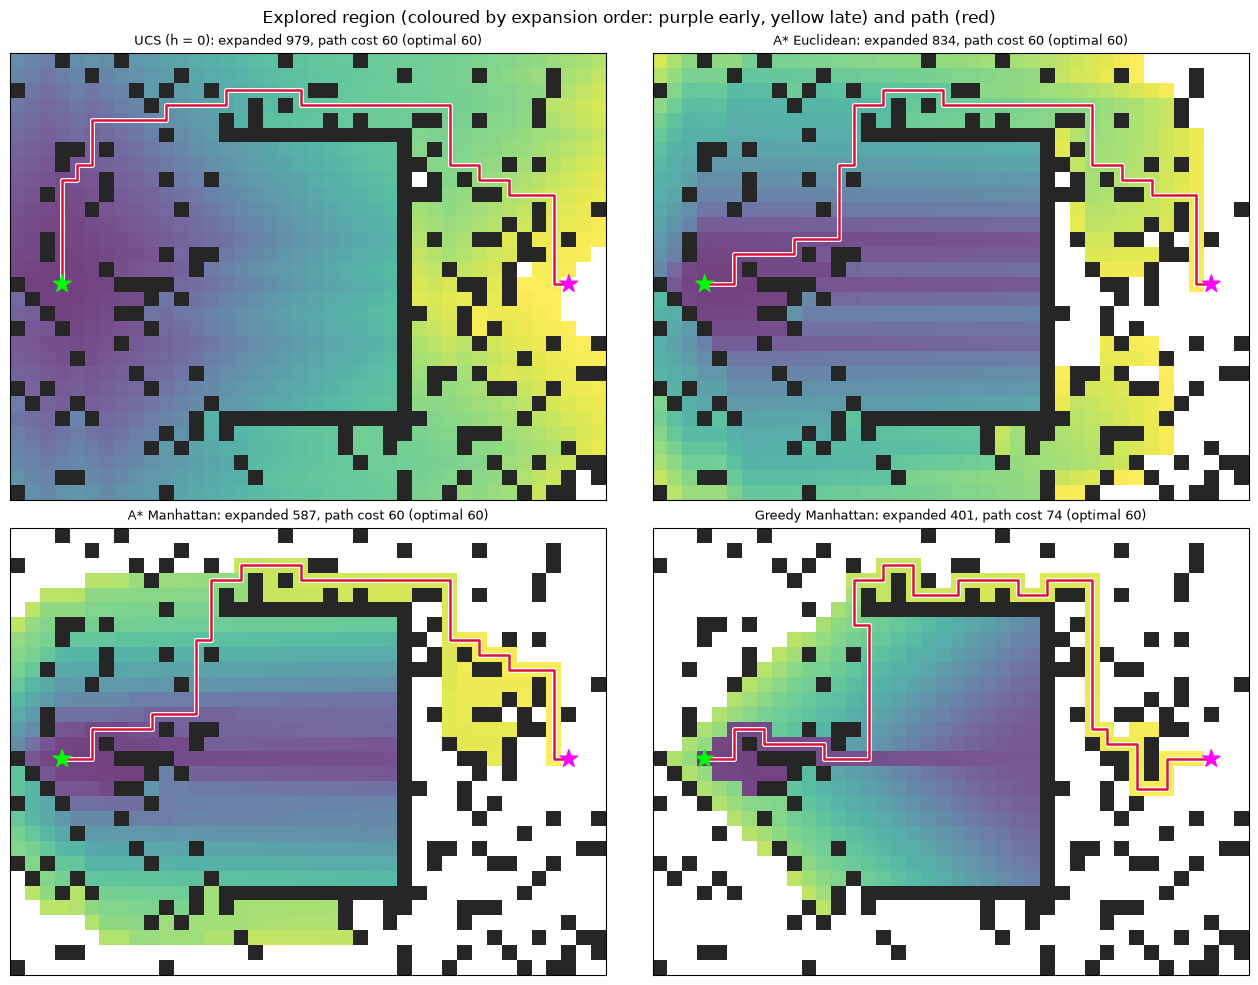

In [9]:
def draw_grid_search(ax, st, node, title):
    img = np.ones(GRID.shape + (3,)); img[GRID == 1] = (0.15, 0.15, 0.15)
    ax.imshow(img)
    order = np.full(GRID.shape, np.nan)
    for i, s in enumerate(st.expanded):
        if np.isnan(order[s]): order[s] = i
    ax.imshow(np.ma.masked_invalid(order), cmap="viridis", alpha=0.75)
    pr, pc = zip(*path_states(node))
    ax.plot(pc, pr, color="white", lw=3.5); ax.plot(pc, pr, color="crimson", lw=1.8)
    ax.scatter([START[1], GOAL[1]], [START[0], GOAL[0]], marker="*", s=170, color=["lime", "magenta"], zorder=4)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (name, (node, st)) in zip(axes.ravel(), grid_runs.items()):
    draw_grid_search(ax, st, node, f"{name}: expanded {len(st.expanded)}, path cost {node.path_cost} (optimal {OPT})")
plt.suptitle("Explored region (coloured by expansion order: purple early, yellow late) and path (red)")
plt.tight_layout(); plt.show()

**What just happened?**
- **UCS** ($h = 0$) explores in every direction, including straight *away* from the goal. It expands the most squares.
- **A\* Euclidean** leans towards the goal but explores a wide band, because the Euclidean estimate is often well below the true cost on a 4-way grid.
- **A\* Manhattan** explores the least of the three optimal searches. It still has to fill the U-shaped trap: inside the U, the heuristic promises a short distance that the wall makes impossible. Once the U is "flooded", the higher $f$ values make A\* go around it.
- **Greedy** runs straight into the U, because it only looks at $h$. Every square inside the U looks close to the goal, so greedy fills it before escaping round the top. The path it returns follows its parent pointers and keeps part of that detour: **74 steps instead of 60** (23% longer). It expanded the fewest nodes (401), but its answer is wrong.

All the claims are checked by `assert`: the three A\* variants (including UCS) are optimal according to NetworkX; greedy is not; and a better-informed heuristic means fewer nodes expanded.

**Complexity of A\*.** With a perfect heuristic ($h = h^*$), A\* would walk straight to the goal. In general, the number of nodes expanded is the number of states with $f(n) < C^*$, plus some with $f(n) = C^*$. This is exponential in the worst case: if the heuristic's error grows with the solution length, A\* is still $O(b^d)$. A\* keeps every generated node in memory, so **space is A\*'s main weakness** (Sections 7 and 10).

**A\* is optimally efficient** (for a consistent heuristic, ignoring ties): no other optimal algorithm that extends search paths from the root with the same heuristic is guaranteed to expand fewer nodes. Any such algorithm must expand every node with $f(n) < C^*$, or it could miss a better solution.

## 5. The 8-puzzle

> 💬 **In plain English:** half of all sliding-puzzle layouts can never be solved, and a better guess solves the rest much faster.

### 5.1 Solvability: half of all layouts can never be solved

An **inversion** is a pair of tiles (ignoring the blank) that appear in the wrong order when you read the board row by row. For example, in `1 2 3 / 4 5 6 / 8 7 _` the pair (8, 7) is the only inversion.

**Rule for a 3 × 3 board:** a layout can reach the goal `1 2 3 / 4 5 6 / 7 8 _` **if and only if its number of inversions is even**.

**Why?** A *horizontal* move swaps the blank with a neighbour, so the reading order of the tiles doesn't change: inversions stay the same. A *vertical* move takes one tile and jumps it over the 2 tiles between its old and new position in reading order. That changes the number of inversions by +2, 0 or −2. Either way the **parity** (even/odd) never changes. The goal has 0 inversions (even), so only even layouts can reach it. (For boards of even width, such as the 15-puzzle, the rule also involves the blank's row.)

We check the rule against brute force: a BFS from the goal finds every reachable state.

In [10]:
GOAL8 = (1, 2, 3, 4, 5, 6, 7, 8, 0)

class EightPuzzle(Problem):
    DELTAS = {"Up": -3, "Down": 3, "Left": -1, "Right": 1}
    def __init__(self, initial):
        super().__init__(initial, GOAL8)
    def actions(self, s):
        r, c = divmod(s.index(0), 3)
        return [a for a, ok in (("Up", r > 0), ("Down", r < 2), ("Left", c > 0), ("Right", c < 2)) if ok]
    def result(self, s, a):
        i = s.index(0); j = i + self.DELTAS[a]
        t = list(s); t[i], t[j] = t[j], t[i]
        return tuple(t)

def inversions(state):
    tiles = [t for t in state if t != 0]                       # ignore the blank
    return sum(1 for i in range(len(tiles)) for j in range(i + 1, len(tiles)) if tiles[i] > tiles[j])

def is_solvable(state):
    return inversions(state) % 2 == 0

# Brute force: BFS from the goal gives the exact distance h*(s) of every reachable state.
t0 = time.perf_counter()
H_STAR = {GOAL8: 0}
ADJ = {}                                                     # state -> neighbouring states (reused below)
queue = deque([GOAL8]); helper = EightPuzzle(GOAL8)
while queue:
    s = queue.popleft()
    ADJ[s] = [helper.result(s, a) for a in helper.actions(s)]
    for s2 in ADJ[s]:
        if s2 not in H_STAR:
            H_STAR[s2] = H_STAR[s] + 1; queue.append(s2)
print(f"BFS from the goal: {len(H_STAR):,} reachable states in {time.perf_counter() - t0:.1f}s; "
      f"the hardest need {max(H_STAR.values())} moves")

# Check the inversion rule on ALL 9! = 362,880 layouts.
agree = sum(is_solvable(p) == (p in H_STAR) for p in itertools.permutations(range(9)))
print(f"inversion rule agrees with brute force on {agree:,} of {math.factorial(9):,} layouts")
assert agree == math.factorial(9)
print("example: 1 2 3 / 4 5 6 / 8 7 _ has", inversions((1, 2, 3, 4, 5, 6, 8, 7, 0)), "inversion -> solvable?",
      is_solvable((1, 2, 3, 4, 5, 6, 8, 7, 0)))

BFS from the goal: 181,440 reachable states in 5.9s; the hardest need 31 moves


inversion rule agrees with brute force on 362,880 of 362,880 layouts
example: 1 2 3 / 4 5 6 / 8 7 _ has 1 inversion -> solvable? False


**What just happened?** Exactly half of the 362,880 layouts (181,440) are reachable, and the inversion-parity rule predicts reachability correctly for **every** layout. The famous "swap 7 and 8" puzzle has 1 inversion, so it cannot be solved. (In the 1880s the puzzle-maker Sam Loyd publicised a $1,000 prize for solving the 15-puzzle with tiles 14 and 15 swapped. It was safe: that position has odd parity and can never be solved.) Always run `is_solvable` before searching: on an unsolvable puzzle, an uninformed search would grind through all 181,440 reachable states before reporting failure.

### 5.2 Two heuristics, and where they come from

| Heuristic | Definition | Example: `7 2 4 / 5 _ 6 / 8 3 1` (AIMA's start state, with our goal) |
|---|---|---|
| $h_1$ **misplaced tiles** | number of tiles (not the blank) not in their goal square | computed below |
| $h_2$ **Manhattan distance** | sum over tiles of $|\Delta \text{row}| + |\Delta \text{col}|$ to the tile's goal square | computed below |

**Relaxed problems.** Both heuristics are exact solution costs of *easier* versions of the puzzle. The real rule is: *a tile can move from square A to square B if A is adjacent to B **and** B is blank.* Remove conditions to get a **relaxed problem**:

| Relaxed rule | Exact cost of the relaxed problem |
|---|---|
| a tile can move to any square (drop both conditions) | $h_1$: each misplaced tile needs exactly 1 move |
| a tile can move to any *adjacent* square, even if occupied (drop "B is blank") | $h_2$: each tile walks its Manhattan distance |
| a tile can move from A to B if B is blank (drop "adjacent") | Gaschnig's heuristic |

**Why are these admissible?** A relaxed problem has *more* actions, so every solution of the real problem is also a solution of the relaxed one. The relaxed optimum can only be cheaper or equal: $h_{\text{relaxed}}^*(n) \le h^*(n)$. The cost of an optimal solution to a relaxed problem is also **consistent**, because it is an exact distance in a bigger graph and so obeys the triangle inequality.

In [11]:
GOAL_POS = {tile: divmod(i, 3) for i, tile in enumerate(GOAL8)}     # tile -> (row, col) in the goal

def h1_misplaced(s):
    return sum(1 for i, t in enumerate(s) if t != 0 and t != GOAL8[i])

def h2_manhattan(s):
    total = 0
    for i, t in enumerate(s):
        if t != 0:
            r, c = divmod(i, 3); gr, gc = GOAL_POS[t]
            total += abs(r - gr) + abs(c - gc)
    return total

def show(s):
    return " / ".join(" ".join("_" if v == 0 else str(v) for v in s[r * 3:r * 3 + 3]) for r in range(3))

aima_start = (7, 2, 4, 5, 0, 6, 8, 3, 1)
print(show(aima_start), "| solvable:", is_solvable(aima_start), "| h1 =", h1_misplaced(aima_start),
      "| h2 =", h2_manhattan(aima_start), "| true h* =", H_STAR.get(aima_start))

# Exhaustive checks over all 181,440 states and all their moves (every move costs 1).
states = list(H_STAR)
H1 = {s: h1_misplaced(s) for s in states}      # precompute both heuristics once; the experiments
H2 = {s: h2_manhattan(s) for s in states}      # below look them up, which is much faster
checks = {
    "h1 admissible": all(H1[s] <= H_STAR[s] for s in states),
    "h2 admissible": all(H2[s] <= H_STAR[s] for s in states),
    "h1 consistent": all(H1[s] <= 1 + H1[t] for s in states for t in ADJ[s]),
    "h2 consistent": all(H2[s] <= 1 + H2[t] for s in states for t in ADJ[s]),
    "h2 dominates h1 (h2 >= h1 everywhere)": all(H2[s] >= H1[s] for s in states),
}
for k, v in checks.items():
    print(f"{k:<40} {v}")
assert all(checks.values())
gap = pd.DataFrame({"h*": [H_STAR[s] for s in states], "h1": [H1[s] for s in states], "h2": [H2[s] for s in states]})
print("\naverage over all states:", gap.mean().round(2).to_dict())

7 2 4 / 5 _ 6 / 8 3 1 | solvable: True | h1 = 6 | h2 = 14 | true h* = 20


h1 admissible                            True
h2 admissible                            True
h1 consistent                            True
h2 consistent                            True
h2 dominates h1 (h2 >= h1 everywhere)    True



average over all states: {'h*': 21.97, 'h1': 7.11, 'h2': 14.0}


**What just happened?** For AIMA's start state (with our goal), the misplaced-tiles count is small, the Manhattan distance is larger, and the true cost is larger still. The exhaustive checks prove, for **every** one of the 181,440 states:
- both heuristics are admissible and consistent;
- $h_2 \ge h_1$ everywhere: **$h_2$ dominates $h_1$**.

**Dominance.** If $h_2(n) \ge h_1(n)$ for all $n$ and both are admissible, then A\* with $h_2$ never expands more nodes than A\* with $h_1$ (except possibly for ties). *Why:* A\* surely expands every node with $f(n) < C^*$, that is, with $h(n) < C^* - g(n)$. Any node this condition selects under $h_2$ is also selected under $h_1$, since $h_1 \le h_2$. **A larger admissible heuristic is always better**, as long as it is cheap to compute.

**Combining heuristics.** If you have several admissible heuristics and none dominates, use $h(n) = \max(h_a(n), h_b(n), \dots)$. It is admissible, dominates each of them, and is consistent if they all are.

Now we race UCS, A\*($h_1$) and A\*($h_2$) on puzzles of known difficulty.

In [12]:
by_depth = {}
for s, d in H_STAR.items():
    by_depth.setdefault(d, []).append(s)
rng = random.Random(SEED)
demo = rng.choice(by_depth[20])                          # one puzzle that needs exactly 20 moves
print("puzzle:", show(demo), "| h* =", H_STAR[demo], "| h1 =", h1_misplaced(demo), "| h2 =", h2_manhattan(demo))
rows = []
for name, run in [("UCS (h = 0)", lambda pr: ucs(pr)),
                  ("A* h1 misplaced", lambda pr: astar(pr, h1_misplaced)),
                  ("A* h2 Manhattan", lambda pr: astar(pr, h2_manhattan))]:
    t0 = time.perf_counter()
    node, st = run(EightPuzzle(demo))
    rows.append({"search": name, "moves": node.path_cost, "nodes expanded": len(st.expanded),
                 "nodes generated": st.generated, "seconds": round(time.perf_counter() - t0, 3)})
    assert node.path_cost == H_STAR[demo]                 # optimal, checked against the exact table
print(pd.DataFrame(rows).set_index("search").to_string())

puzzle: 5 8 3 / 2 _ 4 / 1 6 7 | h* = 20 | h1 = 7 | h2 = 14


                 moves  nodes expanded  nodes generated  seconds
search                                                          
UCS (h = 0)         20           61768           164384    2.014
A* h1 misplaced     20            2760             7526    0.225
A* h2 Manhattan     20             169              453    0.005


**What just happened?** All three searches found an optimal 20-move solution (checked against the exact BFS table). UCS expanded tens of thousands of states, A\* with $h_1$ a few thousand, and A\* with $h_2$ fewer than two hundred. The better heuristic does a small fraction of the work.

## 6. Effective branching factor

> 💬 **In plain English:** one number that says how good a heuristic is: the closer to 1, the better.

How do you summarise "how good is this heuristic" in one number? If A\* generates $N$ nodes for a solution at depth $d$, the **effective branching factor** $b^*$ is the branching factor that a *uniform* tree of depth $d$ would need to contain $N + 1$ nodes:

$$N + 1 = 1 + b^* + (b^*)^2 + \dots + (b^*)^d.$$

For example, if A\* finds a depth-5 solution after generating 52 nodes, then $b^* \approx 1.92$. A good heuristic has $b^*$ close to 1, and $b^*$ stays fairly constant across problem sizes, so it is a fair way to compare heuristics.

We solve the equation for $b^*$ by **bisection**, then rebuild AIMA's famous table (Figure 3.26) with our own code: 20 random puzzles per depth, BFS (only up to depth 16) vs A\*($h_1$) vs A\*($h_2$).

In [13]:
def effective_branching_factor(N, d, tol=1e-6):
    # Solve N + 1 = 1 + b + b^2 + ... + b^d for b by bisection.
    if d == 0:
        return float("nan")
    total = lambda b: sum(b ** i for i in range(d + 1))
    lo, hi = 1.0, max(2.0, float(N))
    while hi - lo > tol:
        mid = (lo + hi) / 2
        if total(mid) < N + 1: lo = mid
        else: hi = mid
    return (lo + hi) / 2

print("b* for N = 52, d = 5:", round(effective_branching_factor(52, 5), 2))
assert abs(effective_branching_factor(52, 5) - 1.92) < 0.01

def bfs_generated(problem):
    # Plain BFS (early goal test); returns (depth, nodes generated).
    if problem.is_goal(problem.initial): return 0, 0
    frontier, reached, generated = deque([Node(problem.initial)]), {problem.initial}, 0
    while frontier:
        node = frontier.popleft()
        for child in expand(problem, node):
            generated += 1
            if problem.is_goal(child.state): return child.depth, generated
            if child.state not in reached:
                reached.add(child.state); frontier.append(child)

t0 = time.perf_counter()
rng = random.Random(2024)
rows = []
for d in range(2, 25, 2):
    for s in rng.sample(by_depth[d], min(20, len(by_depth[d]))):   # depth 2 has fewer than 20 states
        pr = EightPuzzle(s)
        n1, st1 = astar(pr, H1.__getitem__)                 # same values as h1_misplaced, looked up
        n2, st2 = astar(pr, H2.__getitem__)
        assert n1.path_cost == n2.path_cost == d            # both optimal
        row = {"d": d, "A*(h1)": st1.generated, "A*(h2)": st2.generated}
        if d <= 16:
            depth_bfs, gen_bfs = bfs_generated(pr)
            assert depth_bfs == d
            row["BFS"] = gen_bfs
        rows.append(row)
raw = pd.DataFrame(rows)
mean_nodes = raw.groupby("d").mean()
ebf = mean_nodes.apply(lambda col: [effective_branching_factor(n, d) if not np.isnan(n) else np.nan
                                    for d, n in zip(col.index, col.values)])
ebf_table = pd.concat({"nodes generated (mean of 20)": mean_nodes[["BFS", "A*(h1)", "A*(h2)"]].round(0),
                       "effective branching factor b*": ebf[["BFS", "A*(h1)", "A*(h2)"]].round(2)}, axis=1)
print(ebf_table.to_string())
print(f"\n({len(raw)} puzzles solved three ways in {time.perf_counter() - t0:.1f}s)")
assert (mean_nodes["A*(h2)"] <= mean_nodes["A*(h1)"]).all()

b* for N = 52, d = 5: 1.92


   nodes generated (mean of 20)                  effective branching factor b*              
                            BFS   A*(h1)  A*(h2)                           BFS A*(h1) A*(h2)
d                                                                                           
2                           9.0      6.0     6.0                          2.58   2.00   2.00
4                          35.0     12.0    12.0                          2.10   1.49   1.48
6                         121.0     21.0    18.0                          1.99   1.37   1.32
8                         380.0     41.0    26.0                          1.92   1.36   1.26
10                       1032.0     85.0    38.0                          1.85   1.38   1.23
12                       2537.0    189.0    62.0                          1.80   1.40   1.24
14                       6948.0    465.0   100.0                          1.77   1.42   1.24
16                      18639.0   1125.0   241.0                      

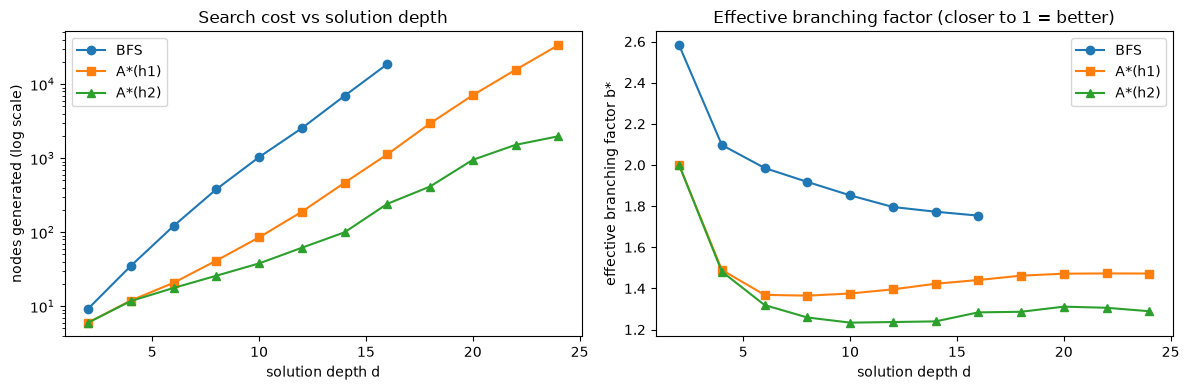

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for col, m in [("BFS", "o"), ("A*(h1)", "s"), ("A*(h2)", "^")]:
    ser = mean_nodes[col].dropna()
    axes[0].semilogy(ser.index, ser.values, marker=m, label=col)
    axes[1].plot(ebf[col].dropna().index, ebf[col].dropna().values, marker=m, label=col)
axes[0].set_xlabel("solution depth d"); axes[0].set_ylabel("nodes generated (log scale)")
axes[0].set_title("Search cost vs solution depth"); axes[0].legend()
axes[1].set_xlabel("solution depth d"); axes[1].set_ylabel("effective branching factor b*")
axes[1].set_title("Effective branching factor (closer to 1 = better)"); axes[1].legend()
plt.tight_layout(); plt.show()

**What just happened?** These are our own numbers for AIMA's classic experiment:
- BFS's $b^*$ is about 1.8. Each state has 2-4 moves, but one of them undoes the previous move, and graph search also skips any other state it has already reached, so the number of *new* states grows much more slowly than 3 per level. Its cost still explodes with depth, so we stopped it at depth 16.
- A\*($h_1$) has a lower $b^*$, and A\*($h_2$) a much lower one. At depth 24, A\*($h_2$) generates only a small fraction of the nodes A\*($h_1$) needs. On a log scale, that gap is the vertical distance between the two lines.
- $b^*$ is roughly **flat** across depths for each method, which is why it is a useful summary.
- The assert confirms dominance in practice: $h_2$ never needed more nodes than $h_1$ on average.

Our numbers are close to the book's. AIMA reports roughly 39,000 nodes ($b^* \approx 1.48$) for $h_1$ and roughly 1,600 nodes ($b^* \approx 1.26$) for $h_2$ at depth 24, against our 33,562 ($b^*$ 1.47) and 1,974 ($b^*$ 1.29). They differ a little because the puzzles are random and the implementations (and goal layouts) are not identical.

## 7. IDA\*: A\* with the memory of depth-first search

> 💬 **In plain English:** the same answers as A\* while remembering only the current path.

A\*'s weakness is memory: it keeps every generated node. **Iterative-deepening A\*** (IDA\*, Korf 1985) does to A\* what IDS did to BFS:
1. Set a **cutoff** = $f(\text{root}) = h(\text{start})$.
2. Run a depth-first search that prunes any node with $f(n) = g(n) + h(n)$ **greater than the cutoff**.
3. If no goal is found, raise the cutoff to the **smallest $f$ value that was pruned**, and repeat.

Memory is just the current path, $O(bd)$, so IDA\* works on puzzles where A\* would run out of memory (it was the first algorithm to solve random 15-puzzles optimally). With an admissible $h$ it is optimal. The cost: it re-expands nodes in every iteration and, like IDS, it cannot detect repeated states reached by different paths.

In [15]:
def ida_star(problem, h):
    stats = Stats("IDA*")
    iterations = []                                # (cutoff, nodes expanded in that iteration)
    path = [problem.initial]                       # the current path: IDA*'s only memory
    on_path = {problem.initial}
    FOUND = object()

    def search(state, g, cutoff):
        f = g + h(state)
        if f > cutoff:
            return f                               # prune; report the f that exceeded the cutoff
        if problem.is_goal(state):
            return FOUND
        stats.expanded.append(state)
        smallest = math.inf
        for a in problem.actions(state):
            s2 = problem.result(state, a)
            if s2 in on_path:                      # no cycles along the current path
                continue
            stats.generated += 1
            path.append(s2); on_path.add(s2)
            stats.max_memory = max(stats.max_memory, len(path))
            t = search(s2, g + problem.action_cost(state, a, s2), cutoff)
            if t is FOUND:
                return FOUND
            smallest = min(smallest, t)
            path.pop(); on_path.discard(s2)
        return smallest

    cutoff = h(problem.initial)
    while True:
        before = len(stats.expanded)
        t = search(problem.initial, 0, cutoff)
        iterations.append((cutoff, len(stats.expanded) - before))
        if t is FOUND:
            return list(path), stats, iterations
        if t == math.inf:
            return None, stats, iterations
        cutoff = t                                 # next contour

ida_path, ida_stats, its = ida_star(EightPuzzle(demo), h2_manhattan)
print("IDA* moves:", len(ida_path) - 1, "| true h*:", H_STAR[demo])
print(pd.DataFrame(its, columns=["f cutoff", "nodes expanded"]).to_string(index=False))
assert len(ida_path) - 1 == H_STAR[demo]

IDA* moves: 20 | true h*: 20
 f cutoff  nodes expanded
       14              11
       16              57
       18             169
       20             471


**What just happened?** IDA\* started with the cutoff $h_2(\text{start})$ and raised it by 2 each time. (On the 8-puzzle every move changes $g$ by 1 and $h_2$ by exactly ±1, so $f$ always changes by 0 or 2.) The last iteration found an optimal solution.

Now compare memory use on the same 20 depth-24 puzzles: A\* must store its whole frontier and reached set, while IDA\* stores one path.

In [16]:
rows = []
for s in random.Random(5).sample(by_depth[24], 20):
    pr = EightPuzzle(s)
    t0 = time.perf_counter(); n_a, st_a = astar(pr, H2.__getitem__); ta = time.perf_counter() - t0
    t0 = time.perf_counter(); pth, st_i, _ = ida_star(pr, H2.__getitem__); ti = time.perf_counter() - t0
    assert n_a.path_cost == len(pth) - 1 == 24                 # both optimal
    rows.append({"A* expanded": len(st_a.expanded), "A* memory (nodes)": st_a.max_memory, "A* s": ta,
                 "IDA* expanded": len(st_i.expanded), "IDA* memory (path length)": st_i.max_memory, "IDA* s": ti})
mem = pd.DataFrame(rows)
print("Average over 20 puzzles that need 24 moves (h2 heuristic):")
print(mem.mean().round(3).to_string())

Average over 20 puzzles that need 24 moves (h2 heuristic):
A* expanded                   769.350
A* memory (nodes)            1676.750
A* s                            0.032
IDA* expanded                2309.100
IDA* memory (path length)      25.000
IDA* s                          0.060


**What just happened?** IDA\* expanded more nodes than A\* (it repeats work in each iteration and cannot detect states reached by different paths). Its memory, however, never exceeded 25 states (the path), against more than 1,600 nodes on average for A\*. On the 15-puzzle (about $10^{13}$ states), this is the difference between "solved" and "out of memory".

## 8. Weighted A\*: trading optimality for speed

> 💬 **In plain English:** trust the guess more to get an answer faster, accepting a path that may be a little longer.

**Weighted A\*** uses $f(n) = g(n) + w \cdot h(n)$ with $w > 1$. It trusts the heuristic more, so it heads for the goal more eagerly and usually expands fewer nodes.

- $w = 1$: ordinary A\*. $w \to \infty$: greedy best-first search. $h = 0$: UCS.
- The heuristic $w \cdot h$ may overestimate, so the solution may not be optimal. But it is **bounded-suboptimal**: with a consistent $h$, the cost found is at most $w \cdot C^*$. (Proof sketch: every node on the optimal path has $g + w h \le w(g + h) \le w C^*$, so the returned goal must have $f = \text{cost} \le w C^*$.)

This is popular in robotics and games, where a path that is "at most 20% longer, found 10× faster" is a good deal. Let's test several weights on 30 hard 8-puzzles (depth 24) and on the trap grid.

      8-puzzle: mean cost (optimal 24)  8-puzzle: mean nodes expanded  grid: cost (optimal 60)  grid: nodes expanded
w                                                                                                                   
1.00                              24.0                          841.1                       60                   587
1.25                              24.3                          741.2                       60                   609
1.50                              24.6                          554.3                       62                   605
2.00                              26.1                          504.8                       66                   670
3.00                              31.1                          407.2                       68                   729
5.00                              35.3                          257.5                       68                   739


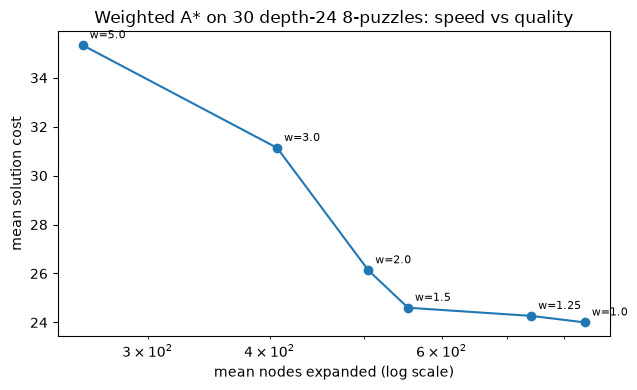

In [17]:
weights = [1.0, 1.25, 1.5, 2.0, 3.0, 5.0]
hard = random.Random(8).sample(by_depth[24], 30)
rows = []
for w in weights:
    costs, nodes = [], []
    for s in hard:
        node, st = weighted_astar(EightPuzzle(s), H2.__getitem__, w)
        assert node.path_cost <= w * H_STAR[s] + 1e-9          # bounded suboptimality
        costs.append(node.path_cost); nodes.append(len(st.expanded))
    g_node, g_st = weighted_astar(grid_problem, h_manhattan, w)
    assert g_node.path_cost <= w * OPT + 1e-9
    rows.append({"w": w, "8-puzzle: mean cost (optimal 24)": np.mean(costs),
                 "8-puzzle: mean nodes expanded": np.mean(nodes),
                 "grid: cost (optimal %d)" % OPT: g_node.path_cost, "grid: nodes expanded": len(g_st.expanded)})
wtable = pd.DataFrame(rows).set_index("w")
print(wtable.round(1).to_string())

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(wtable["8-puzzle: mean nodes expanded"], wtable["8-puzzle: mean cost (optimal 24)"], marker="o")
for w, row in wtable.iterrows():
    ax.annotate(f"w={w}", (row["8-puzzle: mean nodes expanded"], row["8-puzzle: mean cost (optimal 24)"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("mean nodes expanded (log scale)"); ax.set_ylabel("mean solution cost")
ax.set_title("Weighted A* on 30 depth-24 8-puzzles: speed vs quality"); plt.tight_layout(); plt.show()

**What just happened?**
- On the 8-puzzle, $w = 1.5$ saves about a third of the work, and the solutions are barely longer (24.6 moves on average instead of 24). Larger weights save more work but cost more moves: 35.3 on average at $w = 5$.
- Every solution respected the bound cost $\le w \cdot C^*$ (checked by assert), and the actual loss is far below the bound: at $w = 5$ the bound would allow 120 moves.
- On the trap grid the picture is less rosy: larger weights pull the search into the U, much like greedy, and do not always save work. **Weighted A\* helps most when the heuristic is good almost everywhere.** A big local "lie" like the U-trap hurts it.

## 9. When the heuristic overestimates: non-optimal paths

> 💬 **In plain English:** if your guess is too pessimistic about the right road, A\* can miss the best route.

Proof 2 needed $h(n) \le h^*(n)$. What if we break that? We make a deliberately **inadmissible** heuristic for the road map: the straight-line distance, but **+60 km for Glenwood** (someone thinks Glenwood's roads are always jammed). Glenwood is on the optimal route, and its true remaining cost is 58 km, so $h(\text{Glenwood}) \approx 112 > 58$.

In [18]:
def h_pessimistic(city):
    return h_sld(city) + (60 if city == "Glenwood" else 0)

print("h(Glenwood) =", round(h_pessimistic("Glenwood"), 1), " vs true h*(Glenwood) =", h_star["Glenwood"])
print("admissible?", is_admissible(h_pessimistic, h_star, CITY_XY))
bad_node, bad_st = astar(route, h_pessimistic)
good_node, good_st = astar(route, h_sld)
print("A* with SLD          :", " -> ".join(path_states(good_node)), "|", good_node.path_cost, "km")
print("A* with inadmissible :", " -> ".join(path_states(bad_node)), "|", bad_node.path_cost, "km")
assert good_node.path_cost == optimal_km and bad_node.path_cost > optimal_km

# On the 8-puzzle: 3 x Manhattan overestimates. Count how often it loses optimality.
worse, total_nodes_good, total_nodes_bad = 0, 0, 0
for s in hard:
    n_bad, st_bad = astar(EightPuzzle(s), lambda x: 3 * H2[x])
    n_good, st_good = astar(EightPuzzle(s), H2.__getitem__)
    worse += n_bad.path_cost > H_STAR[s]
    total_nodes_bad += len(st_bad.expanded); total_nodes_good += len(st_good.expanded)
print(f"\n8-puzzle, h = 3 x Manhattan: non-optimal on {worse} of {len(hard)} depth-24 puzzles; "
      f"nodes expanded {total_nodes_bad:,} vs {total_nodes_good:,} with admissible h2")
assert worse > 0

h(Glenwood) = 112.2  vs true h*(Glenwood) = 58
admissible? False
A* with SLD          : Ashford -> Cedar Falls -> Elmstead -> Glenwood -> Kingsport -> Lakeside | 141 km
A* with inadmissible : Ashford -> Cedar Falls -> Elmstead -> Juniper -> Kingsport -> Lakeside | 149 km



8-puzzle, h = 3 x Manhattan: non-optimal on 26 of 30 depth-24 puzzles; nodes expanded 12,217 vs 25,232 with admissible h2


**What just happened?** The overestimate made Glenwood look worse than it is. A\* therefore reached Lakeside via Juniper first, with a total of 149 km, and returned it. That is the same mistake greedy made. On the 8-puzzle, tripling the Manhattan distance (equivalent to weighted A\* with $w = 3$) made A\* much faster but returned longer-than-optimal solutions on many of the 30 puzzles.

> ⚠️ **Common mistake:** "I'll multiply my heuristic by 1.5 to make A\* faster, and it's still A\*." It is not: it's weighted A\*, and you lose the optimality guarantee. Sometimes that trade-off is what you want, but make it on purpose.

> 🎓 **Exam / interview tip:** to show a heuristic is **not** admissible, one counterexample state with $h(n) > h^*(n)$ is enough. To show it **is** admissible, argue that it solves a relaxed problem, or prove $h \le h^*$ for all states.

## 10. Memory-bounded search: RBFS and SMA\*

> 💬 **In plain English:** ways to keep searching when the computer's memory runs out.

A\* stores every node it generates. On large problems it runs out of **memory** long before it runs out of time. The main remedies:

| Algorithm | Idea | Memory | Optimal? | Weakness |
|---|---|---|---|---|
| **IDA\*** (Section 7) | depth-first search with an $f$-cutoff, raised iteratively | $O(bd)$ | yes (admissible $h$) | repeats work; struggles when many different $f$ values exist (each iteration may add only one node) |
| **RBFS** (recursive best-first search, Korf 1993) | recursive DFS that remembers the best alternative $f$ at each level; backs up and "forgets" a subtree when it gets worse than the alternative | $O(bd)$ | yes (admissible $h$) | may regenerate the same subtrees many times ("mind changes") |
| **SMA\*** (simplified memory-bounded A\*) | runs like A\* until memory is full; then **drops the worst leaf** (highest $f$) and stores its $f$ value in its parent, so the subtree is regenerated only if everything else looks worse | whatever memory you give it | yes, if the shallowest optimal solution fits in memory | can **thrash** (forget and regenerate repeatedly) on hard problems |
| **Beam search** | keep only the $k$ best nodes at each level; throw away the rest | $O(kd)$ | **no**, not even complete | can discard the only path to the goal |

The general lesson (AIMA): *use all the memory you have*. IDA\* and RBFS use too little; SMA\* uses exactly as much as is available.

**Beam search** is everywhere in modern AI. LLMs use it (with a beam width of 4-10) when decoding translations or captions, to find a high-probability *sequence* of tokens instead of greedily picking the best token one at a time.

## 11. 🔗 How this connects to modern AI

> 💬 **In plain English:** A\* and heuristics power game AI, robots, map apps, and the beam search inside LLMs.

- **Game AI and robotics.** A\* on grids and navigation meshes is the standard way characters move in video games. Mobile robots plan with A\* variants such as D\* Lite (replans quickly when the map changes) and Hybrid A\* (respects a car's turning circle). Weighted A\* is used when a fast, near-optimal path is good enough.
- **Sat-navs and map apps.** Road networks have millions of nodes. Production routers combine A\* with **precomputed heuristics**: ALT (landmarks plus the triangle inequality, a consistent heuristic built from data) and contraction hierarchies.
- **Learned heuristics.** AlphaGo and AlphaZero replace hand-written evaluation with a neural network that estimates how good a state is, and use it to steer tree search (notebook 05 and [`11_Reinforcement_Learning/06_advanced_rl.ipynb`](../../11_Reinforcement_Learning/06_advanced_rl.ipynb)). A value function in RL plays the same role as $h$: see [`11_Reinforcement_Learning/02_dynamic_programming.ipynb`](../../11_Reinforcement_Learning/02_dynamic_programming.ipynb).
- **LLM decoding and reasoning.** **Beam search** is a memory-bounded best-first search over token sequences. "Reasoning" systems that sample many chains of thought and score them with a verifier or reward model are doing heuristic search over partial solutions. See [`08_LLM/18_reasoning_models.ipynb`](../../08_LLM/18_reasoning_models.ipynb) and [`08_LLM/13_inference_optimization.ipynb`](../../08_LLM/13_inference_optimization.ipynb).
- **Planning.** Classical planners search huge state spaces with heuristics computed automatically from relaxed problems (for example, "ignore delete effects"). That is the relaxed-problem idea from Section 5, applied by software instead of by hand.

## 12. Recap

> 💬 **In plain English:** the key ideas of this notebook in a few bullets, then practice.

- A **heuristic** $h(n)$ estimates the remaining cost to the goal. **Best-first search** expands the node with the smallest $f(n)$: $f = h$ is **greedy**, $f = g + h$ is **A\***, $f = g$ is UCS, $f = g + w h$ is **weighted A\***.
- **Admissible:** $h \le h^*$ (never overestimates). **Consistent:** $h(n) \le c(n, a, n') + h(n')$. Consistent ⇒ admissible, but not the other way round.
- **A\* is optimal** with an admissible $h$ (tree-like search, or graph search that re-opens states). With a consistent $h$, $f$ never decreases along a path and the first expansion of every state is final.
- **Greedy** is fast but not optimal: it fell into the U-trap and took the 149 km route.
- **Dominance:** if $h_2 \ge h_1$ and both are admissible, $h_2$ is better. Heuristics come from **relaxed problems**; $\max$ of admissible heuristics is admissible.
- **8-puzzle:** solvable iff the number of inversions is even (checked on all 362,880 layouts). Manhattan dominates misplaced tiles; both are admissible and consistent (checked on all 181,440 states).
- **Effective branching factor** $b^*$ summarises a heuristic's quality; closer to 1 is better.
- **IDA\*** uses $O(bd)$ memory; **weighted A\*** trades optimality (bounded by $w \cdot C^*$) for speed; **SMA\*** and **RBFS** cope with limited memory; **beam search** is memory-bounded but incomplete.
- An **inadmissible** heuristic can return a non-optimal path, as we showed on the map and the 8-puzzle.

## Practice problems

**1. (Easy)** Is $h(n) = 0$ admissible? Consistent? What does A\* become with it?

<details><summary>Show solution</summary>

Yes and yes: $0 \le h^*(n)$ and $0 \le c + 0$ always hold. A\* with $h = 0$ has $f = g$, so it **is** uniform-cost search. It is optimal but uninformed.

</details>

**2. (Easy)** Is the Manhattan distance admissible on a grid where you may also move **diagonally** at cost 1? What would you use instead?

<details><summary>Show solution</summary>

**No.** A diagonal move reduces the Manhattan distance by 2 at a cost of 1, so Manhattan can overestimate: from (0, 0) to (3, 3) it says 6, but 3 diagonal moves cost 3. Use the **Chebyshev distance** $\max(|\Delta r|, |\Delta c|)$, which is exact on an open 8-connected grid with diagonal cost 1. If diagonals cost $\sqrt{2}$, use the **octile distance** $\max + (\sqrt{2} - 1)\min$. Euclidean distance is admissible in both cases, but weaker.

</details>

**3. (Medium, coding)** Implement **Gaschnig's heuristic** (relaxed rule: a tile may move from A to B if B is blank, not necessarily adjacent). Verify on all 181,440 states that it is admissible and dominates $h_1$. Does it dominate $h_2$?

<details><summary>Show solution</summary>

```python
import itertools
from collections import deque

GOAL8 = (1, 2, 3, 4, 5, 6, 7, 8, 0)
POS = {t: divmod(i, 3) for i, t in enumerate(GOAL8)}
def h1(s): return sum(1 for i, t in enumerate(s) if t and t != GOAL8[i])
def h2(s): return sum(abs(divmod(i, 3)[0] - POS[t][0]) + abs(divmod(i, 3)[1] - POS[t][1]) for i, t in enumerate(s) if t)
def h_gaschnig(s):
    """Relaxed rule: a tile may jump to the blank square from anywhere. Count the swaps."""
    s, moves = list(s), 0
    while tuple(s) != GOAL8:
        b = s.index(0)
        if GOAL8[b] != 0:                      # blank sits where tile GOAL8[b] belongs: move that tile in
            j = s.index(GOAL8[b])
        else:                                  # blank is home: swap it with any misplaced tile
            j = next(i for i, t in enumerate(s) if t and t != GOAL8[i])
        s[b], s[j] = s[j], s[b]; moves += 1
    return moves

# exact distances by BFS from the goal
dist = {GOAL8: 0}; q = deque([GOAL8])
while q:
    s = q.popleft(); b = s.index(0); r, c = divmod(b, 3)
    for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
        if 0 <= r + dr < 3 and 0 <= c + dc < 3:
            j = (r + dr) * 3 + c + dc; t = list(s); t[b], t[j] = t[j], t[b]; t = tuple(t)
            if t not in dist: dist[t] = dist[s] + 1; q.append(t)

assert all(h_gaschnig(s) <= d for s, d in dist.items())               # admissible
assert all(h1(s) <= h_gaschnig(s) for s in dist)                      # dominates h1
print("Gaschnig is admissible and dominates h1;",
      "beats h2 on", sum(h_gaschnig(s) > h2(s) for s in dist), "states, loses on", sum(h_gaschnig(s) < h2(s) for s in dist))
```

It is admissible and dominates $h_1$, but it does **not** dominate $h_2$: each heuristic is larger on some states. Taking $\max(h_2, h_{\text{Gaschnig}})$ would give a heuristic that dominates both.

</details>

**4. (Hard, coding)** Implement the **linear-conflict** heuristic: Manhattan distance plus 2 for each tile that must leave its goal row (or column) so that the other tiles in that line can pass it. Verify that it is admissible on all 181,440 states, that it dominates Manhattan, and that it expands fewer nodes. *Careful:* adding 2 for every conflicting **pair** is **not** admissible when three tiles in a line all conflict. Use "line length minus the longest increasing subsequence of goal positions" to count the tiles that must move out.

<details><summary>Show solution</summary>

```python
import heapq, itertools, random
from collections import deque

GOAL8 = (1, 2, 3, 4, 5, 6, 7, 8, 0)
POS = {t: divmod(i, 3) for i, t in enumerate(GOAL8)}
def neighbours(s):
    b = s.index(0); r, c = divmod(b, 3)
    for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
        if 0 <= r + dr < 3 and 0 <= c + dc < 3:
            j = (r + dr) * 3 + c + dc; t = list(s); t[b], t[j] = t[j], t[b]; yield tuple(t)
def h2(s):
    return sum(abs(divmod(i, 3)[0] - POS[t][0]) + abs(divmod(i, 3)[1] - POS[t][1]) for i, t in enumerate(s) if t)

def lis_len(seq):
    """Length of the longest strictly increasing subsequence (n is tiny, O(n^2) is fine)."""
    best = [1] * len(seq)
    for i in range(len(seq)):
        for j in range(i):
            if seq[j] < seq[i]: best[i] = max(best[i], best[j] + 1)
    return max(best, default=0)

def linear_conflict(s):
    """Manhattan + 2 per tile that must leave its goal row/column to let the others pass."""
    extra = 0
    for line in range(3):
        row_goals = [POS[s[line * 3 + c]][1] for c in range(3) if s[line * 3 + c] and POS[s[line * 3 + c]][0] == line]
        col_goals = [POS[s[r * 3 + line]][0] for r in range(3) if s[r * 3 + line] and POS[s[r * 3 + line]][1] == line]
        extra += (len(row_goals) - lis_len(row_goals)) + (len(col_goals) - lis_len(col_goals))
    return h2(s) + 2 * extra

def astar_count(start, h):
    tie = itertools.count(); frontier = [(h(start), next(tie), 0, start)]; g = {start: 0}; expanded = 0
    while frontier:
        f, _, gs, s = heapq.heappop(frontier)
        if gs > g[s]: continue
        if s == GOAL8: return gs, expanded
        expanded += 1
        for t in neighbours(s):
            if t not in g or gs + 1 < g[t]:
                g[t] = gs + 1; heapq.heappush(frontier, (gs + 1 + h(t), next(tie), gs + 1, t))

dist = {GOAL8: 0}; q = deque([GOAL8])                      # exact distances for checking
while q:
    s = q.popleft()
    for t in neighbours(s):
        if t not in dist: dist[t] = dist[s] + 1; q.append(t)
assert all(linear_conflict(s) <= d for s, d in dist.items())            # admissible on all 181,440 states
assert all(linear_conflict(s) >= h2(s) for s in dist)                   # dominates Manhattan
hard = random.Random(1).sample([s for s, d in dist.items() if d == 24], 10)
n2 = sum(astar_count(s, h2)[1] for s in hard); nlc = sum(astar_count(s, linear_conflict)[1] for s in hard)
assert all(astar_count(s, linear_conflict)[0] == dist[s] for s in hard)  # still optimal
print(f"nodes expanded on 10 depth-24 puzzles: Manhattan {n2:,}, linear conflict {nlc:,}")
```

</details>

**5. (Medium, coding)** Write `effective_branching_factor(N, d)` and compute $b^*$ for $(N, d) = (52, 5)$, $(1000, 10)$, $(100, 10)$.

<details><summary>Show solution</summary>

```python
def effective_branching_factor(N, d, tol=1e-9):
    lo, hi = 1.0, max(2.0, float(N))
    while hi - lo > tol:
        mid = (lo + hi) / 2
        if sum(mid ** i for i in range(d + 1)) < N + 1: lo = mid
        else: hi = mid
    return (lo + hi) / 2

for N, d in [(52, 5), (1000, 10), (100, 10)]:
    print(N, d, round(effective_branching_factor(N, d), 3))
assert abs(effective_branching_factor(52, 5) - 1.92) < 0.01
```

</details>

**6. (Medium, conceptual)** Prove that if $h_a$ and $h_b$ are admissible, then $h = \max(h_a, h_b)$ is admissible. If both are consistent, is $h$ consistent?

<details><summary>Show solution</summary>

**Admissible:** for every $n$, $h_a(n) \le h^*(n)$ and $h_b(n) \le h^*(n)$, so the larger of the two is also $\le h^*(n)$.
**Consistent:** suppose $h(n) = h_a(n)$ (the other case is symmetric). Then $h(n) = h_a(n) \le c(n, a, n') + h_a(n') \le c(n, a, n') + \max(h_a(n'), h_b(n')) = c + h(n')$. So yes.

</details>

**7. (Hard, conceptual)** Weighted A\* with $w = 2$ and a consistent heuristic returned a path of cost 30. What can you say about $C^*$? Why might the actual loss be much smaller than the bound?

<details><summary>Show solution</summary>

$30 \le w \cdot C^* = 2C^*$, so $C^* \ge 15$, and of course $C^* \le 30$. The bound is a worst case. Weighted A\* returns the first goal it pops, whose $g + 2h = g$ was the smallest $f$ in the frontier, and in practice nodes on near-optimal paths usually have small $g + 2h$ too. In our 8-puzzle experiment, $w = 2$ gave 26.1 moves on average against an optimum of 24, far below the bound of 48.

</details>

## Further reading

- Russell & Norvig, *Artificial Intelligence: A Modern Approach* (4th ed.), Sections 3.5-3.6 (informed search, heuristic functions).
- Hart, Nilsson & Raphael (1968), *A Formal Basis for the Heuristic Determination of Minimum Cost Paths*, the original A\* paper. Korf (1985), *Depth-first iterative-deepening*, which introduced IDA\*.
- Amit Patel's (Red Blob Games) A\* pages, with interactive heuristics and grid demos: <http://theory.stanford.edu/~amitp/GameProgramming/>.

## Next notebook

➡️ [`04_local_search_and_optimization.ipynb`](04_local_search_and_optimization.ipynb): when only the final state matters, not the path: **hill climbing**, **simulated annealing** and **genetic algorithms**.